In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv(r"X:\PROJETS\PYTHON\Systeme_scoring_risque_credit\backend\data\cs-training.csv")

In [3]:
data

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
149995,149996,0,0.040674,74,0,0.225131,2100.0,4,0,1,0,0.0
149996,149997,0,0.299745,44,0,0.716562,5584.0,4,0,1,0,2.0
149997,149998,0,0.246044,58,0,3870.000000,NaN,18,0,1,0,0.0
149998,149999,0,0.000000,30,0,0.000000,5716.0,4,0,0,0,0.0


In [4]:
data.isna().sum()

Unnamed: 0                                  0
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

In [5]:
# 1. Suppression de la colonne index parasite si elle existe
if 'Unnamed: 0' in data.columns:
    data = data.drop(columns=['Unnamed: 0'])

# 2. Correction des âges aberrants (remplacement de 0 par NaN)
data['age'] = data['age'].replace(0, float('nan'))

# 3. Imputation des valeurs manquantes
# On utilise la médiane pour le revenu mensuel et 0 pour les personnes à charge
data['MonthlyIncome'] = data['MonthlyIncome'].fillna(data['MonthlyIncome'].median())
data['NumberOfDependents'] = data['NumberOfDependents'].fillna(0)

# Vérification du résultat
print("Dimensions finales :", data.shape)
print("Valeurs manquantes restantes :\n", data.isnull().sum())

Dimensions finales : (150000, 11)
Valeurs manquantes restantes :
 SeriousDlqin2yrs                        0
RevolvingUtilizationOfUnsecuredLines    0
age                                     1
NumberOfTime30-59DaysPastDueNotWorse    0
DebtRatio                               0
MonthlyIncome                           0
NumberOfOpenCreditLinesAndLoans         0
NumberOfTimes90DaysLate                 0
NumberRealEstateLoansOrLines            0
NumberOfTime60-89DaysPastDueNotWorse    0
NumberOfDependents                      0
dtype: int64


In [6]:
data['age'] = data['age'].fillna(data['age'].median())

In [7]:
data.isna().sum()

SeriousDlqin2yrs                        0
RevolvingUtilizationOfUnsecuredLines    0
age                                     0
NumberOfTime30-59DaysPastDueNotWorse    0
DebtRatio                               0
MonthlyIncome                           0
NumberOfOpenCreditLinesAndLoans         0
NumberOfTimes90DaysLate                 0
NumberRealEstateLoansOrLines            0
NumberOfTime60-89DaysPastDueNotWorse    0
NumberOfDependents                      0
dtype: int64

In [8]:
data.dtypes

SeriousDlqin2yrs                          int64
RevolvingUtilizationOfUnsecuredLines    float64
age                                     float64
NumberOfTime30-59DaysPastDueNotWorse      int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse      int64
NumberOfDependents                      float64
dtype: object

C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\dell\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


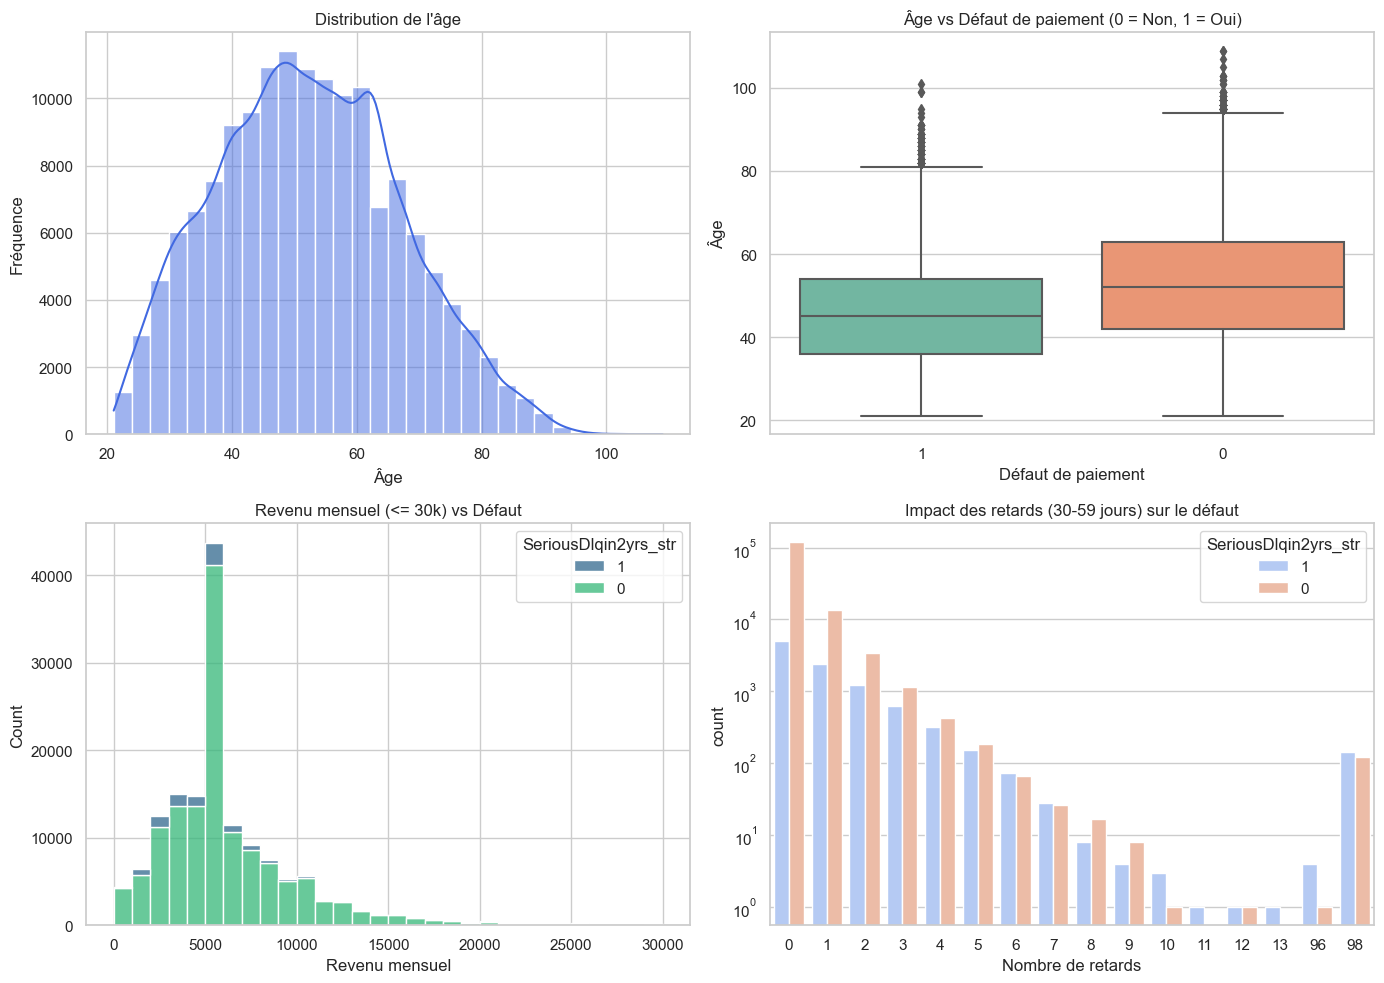

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration du style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 10))

# On convertit la cible en string pour éviter le bug de légende de seaborn avec les entiers
data_viz = data.copy()
data_viz['SeriousDlqin2yrs_str'] = data_viz['SeriousDlqin2yrs'].astype(str)

# 1. Distribution de l'âge
plt.subplot(2, 2, 1)
sns.histplot(data_viz['age'], bins=30, kde=True, color='royalblue')
plt.title("Distribution de l'âge")
plt.xlabel("Âge")
plt.ylabel("Fréquence")

# 2. Relation entre l'âge et le défaut
plt.subplot(2, 2, 2)
sns.boxplot(x='SeriousDlqin2yrs_str', y='age', data=data_viz, palette='Set2')
plt.title("Âge vs Défaut de paiement (0 = Non, 1 = Oui)")
plt.xlabel("Défaut de paiement")
plt.ylabel("Âge")

# 3. Revenu mensuel (filtré pour la lisibilité)
plt.subplot(2, 2, 3)
income_filtered = data_viz[data_viz['MonthlyIncome'] <= 30000]
sns.histplot(data=income_filtered, x='MonthlyIncome', hue='SeriousDlqin2yrs_str', multiple="stack", bins=30, palette='viridis')
plt.title("Revenu mensuel (<= 30k) vs Défaut")
plt.xlabel("Revenu mensuel")

# 4. Nombre d'incidents de retard (30-59 jours)
plt.subplot(2, 2, 4)
sns.countplot(data=data_viz, x='NumberOfTime30-59DaysPastDueNotWorse', hue='SeriousDlqin2yrs_str', palette='coolwarm')
plt.title("Impact des retards (30-59 jours) sur le défaut")
plt.xlabel("Nombre de retards")
plt.yscale('log')

plt.tight_layout()
plt.show()

In [10]:


# Calcul de la matrice de corrélation
corr_matrix = data.corr()

# Affichage de la figure
print(corr_matrix)

                                      SeriousDlqin2yrs  \
SeriousDlqin2yrs                              1.000000   
RevolvingUtilizationOfUnsecuredLines         -0.001802   
age                                          -0.115397   
NumberOfTime30-59DaysPastDueNotWorse          0.125587   
DebtRatio                                    -0.007602   
MonthlyIncome                                -0.017151   
NumberOfOpenCreditLinesAndLoans              -0.029669   
NumberOfTimes90DaysLate                       0.117175   
NumberRealEstateLoansOrLines                 -0.007038   
NumberOfTime60-89DaysPastDueNotWorse          0.102261   
NumberOfDependents                            0.046869   

                                      RevolvingUtilizationOfUnsecuredLines  \
SeriousDlqin2yrs                                                 -0.001802   
RevolvingUtilizationOfUnsecuredLines                              1.000000   
age                                                              -0.0

In [11]:
from sklearn.model_selection import train_test_split
from imblearn.pipeline import Pipeline  # Attention: importer depuis imblearn.pipeline et non sklearn
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# 1. Préparation de X et y (en s'assurant que l'âge est bien imputé)
data['age'] = data['age'].fillna(data['age'].median())
X = data.drop(columns=['SeriousDlqin2yrs'])
y = data['SeriousDlqin2yrs']

# 2. Split Train / Test global (stratifié)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Construction du Pipeline avec SMOTE + Modèle
# Le pipeline applique SMOTE uniquement lors du .fit() sur le train, jamais sur le test
pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])

# 4. Entraînement du pipeline
print("Entraînement du modèle avec Pipeline (SMOTE + Random Forest)...")
pipeline.fit(X_train, y_train)

# 5. Prédictions et Évaluation sur le jeu de test
y_pred = pipeline.predict(X_test)
y_proba = pipeline.predict_proba(X_test)[:, 1]

print("\n--- Performances ---")
print("Score ROC-AUC : {:.4f}".format(roc_auc_score(y_test, y_proba)))
print("\nRapport de classification :")
print(classification_report(y_test, y_proba >= 0.5))

Entraînement du modèle avec Pipeline (SMOTE + Random Forest)...

--- Performances ---
Score ROC-AUC : 0.8237

Rapport de classification :
              precision    recall  f1-score   support

           0       0.96      0.93      0.94     27995
           1       0.30      0.44      0.36      2005

    accuracy                           0.90     30000
   macro avg       0.63      0.68      0.65     30000
weighted avg       0.91      0.90      0.90     30000



In [12]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import classification_report, roc_auc_score

# 1. Définition du Pipeline avec SMOTE et Random Forest
pipeline_rf = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))
])

# 2. Espace des hyperparamètres à explorer aléatoirement
param_distributions = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [10, 20, 30, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__max_features': ['sqrt', 'log2']
}

# 3. Configuration du RandomizedSearchCV (plus rapide avec n_iter=6 et cv=3)
random_search = RandomizedSearchCV(
    estimator=pipeline_rf,
    param_distributions=param_distributions,
    n_iter=6,             # On teste 6 combinaisons aléatoires différentes
    scoring='roc_auc',
    cv=3,                 # 3 plis pour aller vite
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# 4. Lancement de la recherche rapide sur le train
print("Lancement du RandomizedSearchCV...")
random_search.fit(X_train, y_train)

# 5. Meilleurs paramètres et évaluation sur le jeu de test
print("\nMeilleurs hyperparamètres trouvés :")
print(random_search.best_params_)

best_model = random_search.best_estimator_
y_pred_rand = best_model.predict(X_test)
y_proba_rand = best_model.predict_proba(X_test)[:, 1]

print("\n--- Performances après RandomizedSearchCV ---")
print("Score ROC-AUC : {:.4f}".format(roc_auc_score(y_test, y_proba_rand)))
print("\nRapport de classification :")
print(classification_report(y_test, y_pred_rand))

Lancement du RandomizedSearchCV...
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Meilleurs hyperparamètres trouvés :
{'classifier__n_estimators': 100, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 10}

--- Performances après RandomizedSearchCV ---
Score ROC-AUC : 0.8416

Rapport de classification :
              precision    recall  f1-score   support

           0       0.97      0.83      0.89     27995
           1       0.22      0.69      0.34      2005

    accuracy                           0.82     30000
   macro avg       0.60      0.76      0.61     30000
weighted avg       0.92      0.82      0.86     30000



<Figure size 800x600 with 0 Axes>

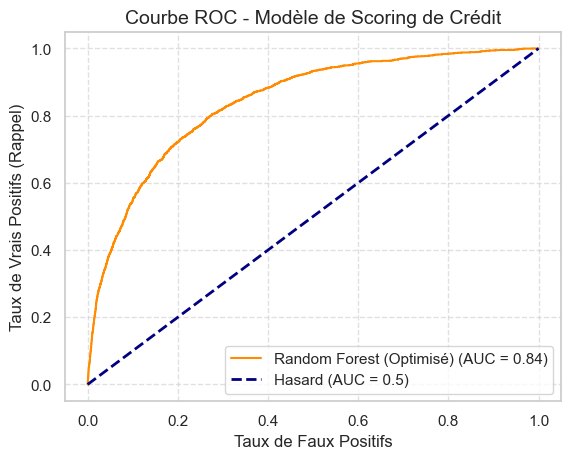

<Figure size 600x600 with 0 Axes>

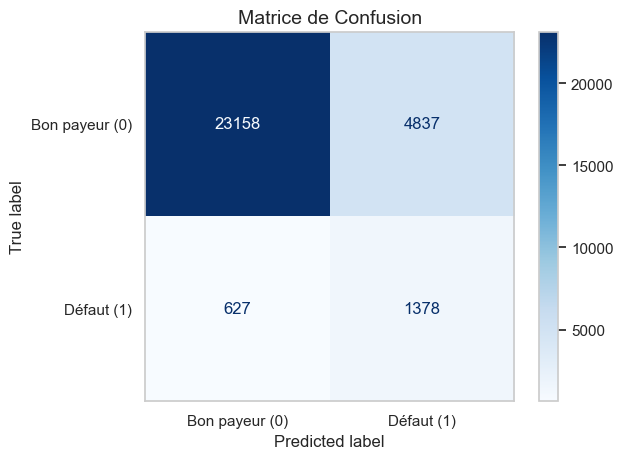

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

# 1. Affichage de la Courbe ROC
plt.figure(figsize=(8, 6))
RocCurveDisplay.from_estimator(best_model, X_test, y_test, name="Random Forest (Optimisé)", color="darkorange")
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--", label="Hasard (AUC = 0.5)")
plt.title("Courbe ROC - Modèle de Scoring de Crédit", fontsize=14)
plt.xlabel("Taux de Faux Positifs", fontsize=12)
plt.ylabel("Taux de Vrais Positifs (Rappel)", fontsize=12)
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 2. Affichage de la Matrice de Confusion
plt.figure(figsize=(6, 6))
ConfusionMatrixDisplay.from_estimator(
    best_model, 
    X_test, 
    y_test, 
    display_labels=['Bon payeur (0)', 'Défaut (1)'], 
    cmap=plt.cm.Blues,
    values_format='d'
)
plt.title("Matrice de Confusion", fontsize=14)
plt.grid(False) # On enlève la grille pour garder une matrice propre
plt.show()

In [15]:
import os
import joblib

# 1. Définition du chemin cible
dossier_destination = r"X:\PROJETS\PYTHON\Systeme_scoring_risque_credit\backend\models"

# 2. S'assurer que le dossier existe (le crée si ce n'est pas déjà fait)
os.makedirs(dossier_destination, exist_ok=True)

# 3. Chemin complet du fichier de sauvegarde
chemin_modele = os.path.join(dossier_destination, "credit_scoring_model.pkl")

# 4. Sauvegarde du meilleur modèle (best_model)
joblib.dump(best_model, chemin_modele)

print(f"Modèle sauvegardé avec succès à l'emplacement :\n{chemin_modele}")

Modèle sauvegardé avec succès à l'emplacement :
X:\PROJETS\PYTHON\Systeme_scoring_risque_credit\backend\models\credit_scoring_model.pkl
